In [1]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# import hvplot.xarray
# from mpl_toolkits.mplot3d import Axes3D
import matplotlib.cm as cm
from scipy.optimize import curve_fit

[ 1.56324082e-09 -1.85886540e-08 -7.75096817e-06  6.37722672e-05
  1.25919448e-01 -1.06698154e-01]


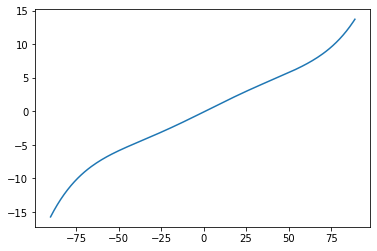

In [2]:
calib_dir = 'C:/Users/RalphGroup/Documents/group_code/daedalus_control/calibrations/2025-06-27_daedalus_calib/'
radial_polar_coeff= np.loadtxt(calib_dir + 'daedalus_radial_polar_calib.csv', delimiter=',')
radial_polar_calib = np.poly1d(radial_polar_coeff)
theta = np.arange(-90, 90, 1)
plt.plot(theta, radial_polar_calib(theta))
print(radial_polar_coeff)

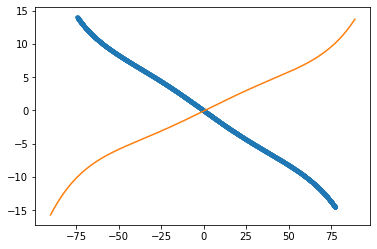

In [11]:
measured = pd.read_csv('2026-06-12/phi0_daedalus_radialPolar_calib_A000.0_2026-06-12_2.csv', comment = '#', index_col = 'theta')
ds = xr.Dataset(measured)
ds = ds.where(ds.R < 14, drop=True)
plt.plot(ds['theta'], ds['R'],'.')
plt.plot(theta, radial_polar_calib(theta))

[-2.33120432e-09 -8.91076829e-09  1.21943209e-05  6.84544796e-06
 -1.81242252e-01  6.29546464e-03]


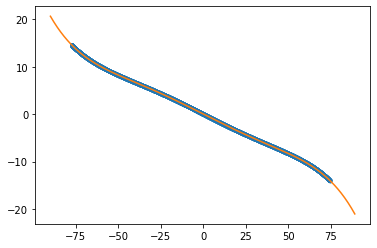

In [12]:
theta = np.arange(-90, 90, 1)
#plt.plot(theta, radial_polar_calib(theta))
plt.plot(-ds['theta'], -ds['R'], '.')

radial_polar_coeff_new = np.polyfit(-ds['theta'], -ds['R'], 5)
print(radial_polar_coeff_new)
radial_polar_calib_new = np.poly1d(radial_polar_coeff_new)
plt.plot(theta, radial_polar_calib_new(theta))

[ 2.33120432e-09  8.91076829e-09 -1.21943209e-05 -6.84544796e-06
  1.81242252e-01 -6.29546464e-03]


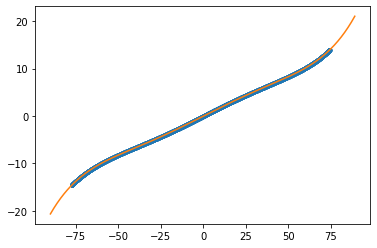

In [13]:
theta = np.arange(-90, 90, 1)
#plt.plot(theta, radial_polar_calib(theta))
plt.plot(-ds['theta'], ds['R'], '.')

radial_polar_coeff_new = np.polyfit(-ds['theta'], ds['R'], 5)
print(radial_polar_coeff_new)
radial_polar_calib_new = np.poly1d(radial_polar_coeff_new)
plt.plot(theta, radial_polar_calib_new(theta))
#save to radial_polar (radial_polar)

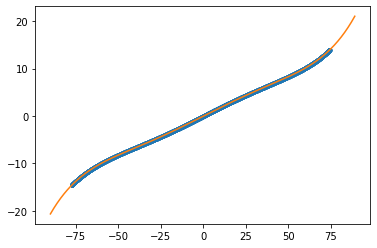

In [15]:
measured90 = pd.read_csv('2026-06-10/phi90_check_daedalus_radialPolar_calib_A090.0_2026-06-10_1.csv', comment = '#', index_col = 'theta')
ds90 = xr.Dataset(measured)
ds90 = ds90.where(ds90.R < 14, drop=True)
plt.plot(-ds90['theta'], ds90['R'],'.')

plt.plot(theta, radial_polar_calib_new(theta))